<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_24_vol3_penguins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#펭귄 멀티클래스

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)

In [2]:
from sklearn.metrics import accuracy_score,precision_score
from sklearn.metrics import recall_score,f1_score
from sklearn.metrics import confusion_matrix

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    pre = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"정확도 {acc}")
    print(f"정밀도 {pre}")
    print(f"재현율 {recall}")
    print(f"f1 {f1}")

    cfm = confusion_matrix(y_true,y_pred)

    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.show()

In [3]:
!wget https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/penguins.csv

--2025-12-24 05:12:26--  https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/penguins.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13523 (13K) [text/plain]
Saving to: ‘penguins.csv’

penguins.csv        100%[===================>]  13.21K  --.-KB/s    in 0s      

2025-12-24 05:12:26 (93.0 MB/s) - ‘penguins.csv’ saved [13523/13523]



In [4]:
df = pd.read_csv('penguins.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Species             344 non-null    object 
 1   Island              344 non-null    object 
 2   Culmen Length(mm)   342 non-null    float64
 3   Culmen Depth(mm)    342 non-null    float64
 4   Flipper Length(mm)  342 non-null    float64
 5   Body Mass(g)        342 non-null    float64
 6   Sex                 334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [7]:
df.shape

(344, 7)

##EDA

##타깃값

In [8]:
df.head()

,Species,Island,Culmen Length(mm),Culmen Depth(mm),Flipper Length(mm),Body Mass(g),Sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [13]:
df.columns.to_list()

['Species',
 'Island',
 'Culmen Length(mm)',
 'Culmen Depth(mm)',
 'Flipper Length(mm)',
 'Body Mass(g)',
 'Sex']

In [14]:
df.columns =[
 'species',
 'island',
 'culmen_length',
 'culmen_depth',
 'flipper_length',
 'body_mass',
 'sex']

In [16]:
df["species"].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
culmen_length,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


In [18]:
df['island'].value_counts()

,count
island,
Biscoe,168
Dream,124
Torgersen,52


In [19]:
df['sex'].value_counts()

,count
sex,
MALE,168
FEMALE,165
.,1


In [20]:
df[df['sex']=='.']

,species,island,culmen_length,culmen_depth,flipper_length,body_mass,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


## 데이터 분리

In [21]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df,test_size=0.1,shuffle=True,random_state=SEED)

train, test

(       species     island  culmen_length  culmen_depth  flipper_length  \
 118     Adelie  Torgersen           35.7          17.0           189.0   
 289     Gentoo     Biscoe           50.7          15.0           223.0   
 193  Chinstrap      Dream           46.2          17.5           187.0   
 5       Adelie  Torgersen           39.3          20.6           190.0   
 210  Chinstrap      Dream           50.2          18.8           202.0   
 ..         ...        ...            ...           ...             ...   
 188  Chinstrap      Dream           47.6          18.3           195.0   
 71      Adelie  Torgersen           39.7          18.4           190.0   
 106     Adelie     Biscoe           38.6          17.2           199.0   
 270     Gentoo     Biscoe           46.6          14.2           210.0   
 102     Adelie     Biscoe           37.7          16.0           183.0   
 
      body_mass     sex  
 118     3350.0  FEMALE  
 289     5550.0    MALE  
 193     3650.0  FEM

In [22]:
x_train = train.drop('species',axis = 1)
y_train = train['species']

In [23]:
x_train, y_train

(        island  culmen_length  culmen_depth  flipper_length  body_mass     sex
 118  Torgersen           35.7          17.0           189.0     3350.0  FEMALE
 289     Biscoe           50.7          15.0           223.0     5550.0    MALE
 193      Dream           46.2          17.5           187.0     3650.0  FEMALE
 5    Torgersen           39.3          20.6           190.0     3650.0    MALE
 210      Dream           50.2          18.8           202.0     3800.0    MALE
 ..         ...            ...           ...             ...        ...     ...
 188      Dream           47.6          18.3           195.0     3850.0  FEMALE
 71   Torgersen           39.7          18.4           190.0     3900.0    MALE
 106     Biscoe           38.6          17.2           199.0     3750.0  FEMALE
 270     Biscoe           46.6          14.2           210.0     4850.0  FEMALE
 102     Biscoe           37.7          16.0           183.0     3075.0  FEMALE
 
 [309 rows x 6 columns],
 118       Ad

##데이터 전처리

In [24]:
x_train['sex'].value_counts()

,count
sex,
MALE,153
FEMALE,146
.,1


In [26]:
x_train['sex'] = x_train['sex'].replace(".",np.nan)

In [27]:
x_train['sex'].value_counts()

,count
sex,
MALE,153
FEMALE,146


In [29]:
x_train.isna().sum()

,0
island,0
culmen_length,2
culmen_depth,2
flipper_length,2
body_mass,2
sex,10


In [31]:
#결측치 삭제
x_train = x_train.dropna()

In [32]:
x_train.shape, y_train.shape

((299, 6), (309,))

In [33]:
y_train = y_train[x_train.index]
y_train.shape

(299,)

##인코딩

In [34]:
x_train.head()

,island,culmen_length,culmen_depth,flipper_length,body_mass,sex
118,Torgersen,35.7,17.0,189.0,3350.0,FEMALE
289,Biscoe,50.7,15.0,223.0,5550.0,MALE
193,Dream,46.2,17.5,187.0,3650.0,FEMALE
5,Torgersen,39.3,20.6,190.0,3650.0,MALE
210,Dream,50.2,18.8,202.0,3800.0,MALE


### 인코딩
- island : one - hot encoding
- sex : ordinal encoding
- y(species) : lable encoding

In [35]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output = False)
onehot_columns = ["island"]

In [36]:
island_encoded_array = ohe.fit_transform(x_train[onehot_columns])
island_categories = ohe.get_feature_names_out(onehot_columns)
island_endocded_df = pd.DataFrame(island_encoded_array,columns=island_categories, index=x_train.index)

In [40]:
if 'island' in x_train.columns:
    x_train = x_train.drop(columns=onehot_columns)
x_train = pd.concat([x_train,island_endocded_df],axis = 1)
x_train.head()

,culmen_length,culmen_depth,flipper_length,body_mass,sex,island_Biscoe,island_Dream,island_Torgersen
118,35.7,17.0,189.0,3350.0,FEMALE,0.0,0.0,1.0
289,50.7,15.0,223.0,5550.0,MALE,1.0,0.0,0.0
193,46.2,17.5,187.0,3650.0,FEMALE,0.0,1.0,0.0
5,39.3,20.6,190.0,3650.0,MALE,0.0,0.0,1.0
210,50.2,18.8,202.0,3800.0,MALE,0.0,1.0,0.0


In [41]:
from sklearn.preprocessing import OrdinalEncoder

oe = OrdinalEncoder()
categorical_columns = ['sex']

x_train[categorical_columns] = oe.fit_transform(x_train[categorical_columns])
x_train.head()

,culmen_length,culmen_depth,flipper_length,body_mass,sex,island_Biscoe,island_Dream,island_Torgersen
118,35.7,17.0,189.0,3350.0,0.0,0.0,0.0,1.0
289,50.7,15.0,223.0,5550.0,1.0,1.0,0.0,0.0
193,46.2,17.5,187.0,3650.0,0.0,0.0,1.0,0.0
5,39.3,20.6,190.0,3650.0,1.0,0.0,0.0,1.0
210,50.2,18.8,202.0,3800.0,1.0,0.0,1.0,0.0


In [45]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
itmes = ['Adelie','Gentoo','Chinstrap']

le.fit(itmes)
y_train = le.transform(y_train)

In [47]:
x_test = test.drop('species',axis=1)
y_test = test['species']

In [48]:
x_test['sex'] = x_test['sex'].replace(".",np.nan)

In [49]:
x_test = x_test.dropna()
y_test = y_test[x_test.index]

In [51]:
island_encoded_array = ohe.fit_transform(x_test[onehot_columns])
island_categories = ohe.get_feature_names_out(onehot_columns)
island_endocded_df = pd.DataFrame(island_encoded_array,columns=island_categories, index=x_test.index)

In [52]:
if 'island' in x_test.columns:
    x_test = x_test.drop(columns=onehot_columns)
x_test = pd.concat([x_test,island_endocded_df],axis = 1)
x_test.head()

,culmen_length,culmen_depth,flipper_length,body_mass,sex,island_Biscoe,island_Dream,island_Torgersen
194,50.9,19.1,196.0,3550.0,MALE,0.0,1.0,0.0
157,45.2,17.8,198.0,3950.0,FEMALE,0.0,1.0,0.0
225,46.5,13.5,210.0,4550.0,FEMALE,1.0,0.0,0.0
208,45.2,16.6,191.0,3250.0,FEMALE,0.0,1.0,0.0
318,48.4,14.4,203.0,4625.0,FEMALE,1.0,0.0,0.0


In [53]:
x_test[categorical_columns] = oe.fit_transform(x_test[categorical_columns])
x_test.head()

,culmen_length,culmen_depth,flipper_length,body_mass,sex,island_Biscoe,island_Dream,island_Torgersen
194,50.9,19.1,196.0,3550.0,1.0,0.0,1.0,0.0
157,45.2,17.8,198.0,3950.0,0.0,0.0,1.0,0.0
225,46.5,13.5,210.0,4550.0,0.0,1.0,0.0,0.0
208,45.2,16.6,191.0,3250.0,0.0,0.0,1.0,0.0
318,48.4,14.4,203.0,4625.0,0.0,1.0,0.0,0.0


In [54]:
y_test = le.transform(y_test)

In [60]:
from sklearn.preprocessing import StandardScaler

xss = StandardScaler()
xss.fit(x_train)
x_train_s = xss.transform(x_train)
x_test_s = xss.transform(x_test)

In [55]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=SEED)

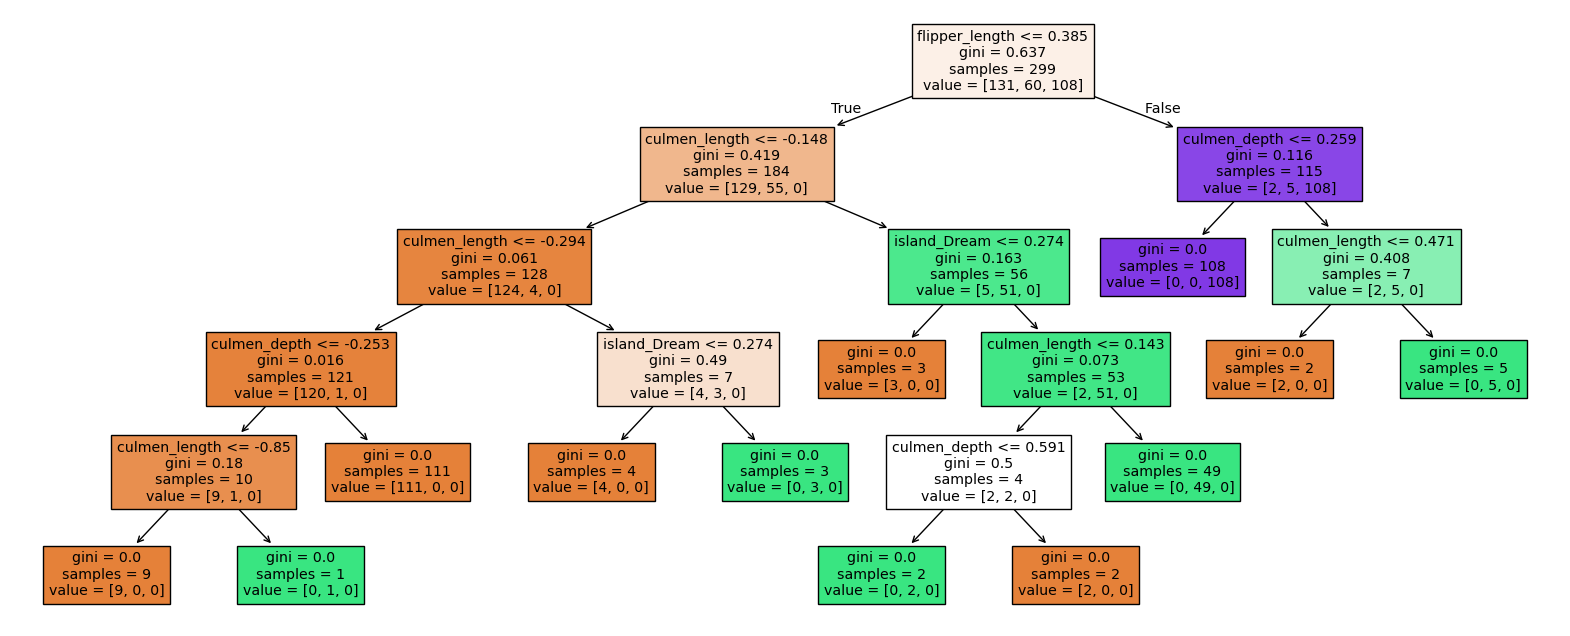

In [65]:
from sklearn.tree import plot_tree

dt.fit(x_train_s,y_train)

plt.figure(figsize=(20,8))
plot_tree(
    decision_tree = dt,
    feature_names = x_train.columns,
    filled= True
)
plt.show()

## 변수 중요도

In [70]:
importances = dt.feature_importances_
col_names = x_train.columns # Changed from x_train_s.columns

importances_df = pd.DataFrame({
    "importances":importances,
    "features":col_names # Changed from features
})

In [71]:
importances_df.sort_values("importances",ascending=False)

,importances,features
2,0.525380,flipper_length
0,0.362659,culmen_length
1,0.066375,culmen_depth
6,0.045586,island_Dream
3,0.000000,body_mass
4,0.000000,sex
5,0.000000,island_Biscoe
7,0.000000,island_Torgersen


In [72]:
y_pred = dt.predict(x_test_s)

정확도 0.9706
정밀도 0.9792
재현율 0.9697
f1 0.9734


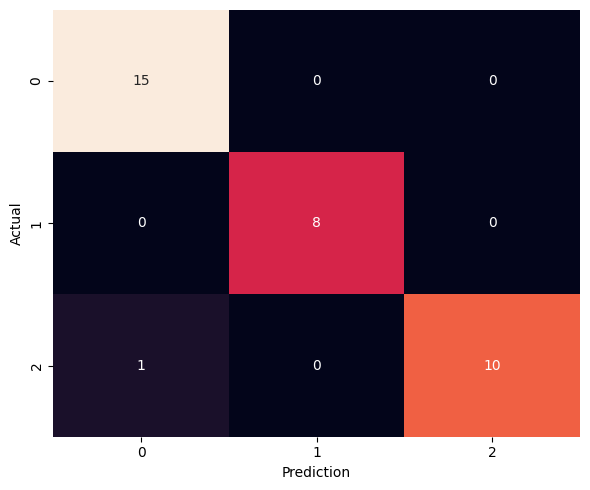

In [75]:
# The original print_metrics function in a previous cell was defined without specifying the 'average' parameter for multiclass metrics.
# For multiclass classification, 'precision_score', 'recall_score', and 'f1_score' require an 'average' parameter
# (e.g., 'micro', 'macro', 'weighted') because 'binary' is the default and is only applicable to binary classification.
# Redefining print_metrics with 'average' parameter to fix this error within this cell.
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns # Ensure seaborn is imported for heatmap

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    # Specify average for multiclass classification, 'macro' is a common choice.
    pre = precision_score(y_true, y_pred, average='macro')
    recall = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')

    print(f"정확도 {acc:.4f}")
    print(f"정밀도 {pre:.4f}")
    print(f"재현율 {recall:.4f}")
    print(f"f1 {f1:.4f}")

    cfm = confusion_matrix(y_true,y_pred)

    plt.figure(figsize=(6, 5)) # Optional: Adjust figure size for better visualization
    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.tight_layout() # Optional: Adjust layout to prevent labels from overlapping
    plt.show()

# Now call the redefined print_metrics function
print_metrics(y_test,y_pred)